In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import keras
from keras import ops
from keras import Input
from keras.models import Sequential
from keras.optimizers import Adam
from keras.layers import Dense, SimpleRNN

import numpy as np

import pandas

keras.utils.set_random_seed(42)

In [2]:
dataframe_raw = pandas.read_csv('ensino_unificado_treino_validacao.csv', delimiter=';', usecols=["ANO","REGIAO","UF","CÓDIGO DO MUNICIPIO","REDE","CÓDIGO DA ESCOLA","Aprovação no 1º Ano do Ensino Fundamental"])

####remocao


<Axes: >

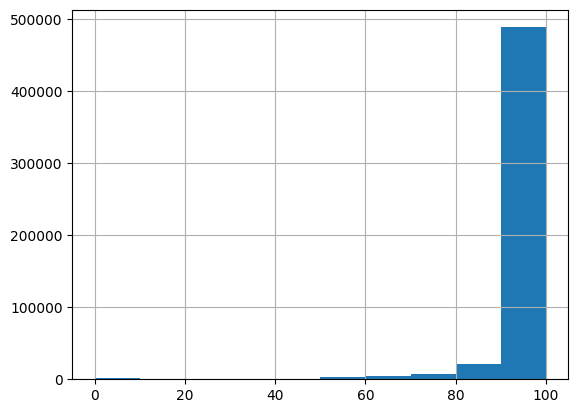

In [3]:
import matplotlib.pyplot as plt

# Filtrando o dataframe para o período de interesse
dataframe_filtrado = dataframe_raw[(dataframe_raw["ANO"] >= 2014) & (dataframe_raw["ANO"] <= 2019)]

dataframe_filtrado["Aprovação no 1º Ano do Ensino Fundamental"].hist()


Análise dos dados

,ANO,mean,median,std
0,2014,96.980520,100.0,9.704799
1,2015,97.108953,100.0,9.546689
2,2016,97.156220,100.0,9.597107
3,2017,97.471379,100.0,8.847191
4,2018,97.594132,100.0,8.528716
5,2019,98.044477,100.0,7.662018


/tmp/ipykernel_3337/1455513259.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[1], x="ANO", y="Aprovação no 1º Ano do Ensino Fundamental", data=dataframe_filtrado, palette="Blues")


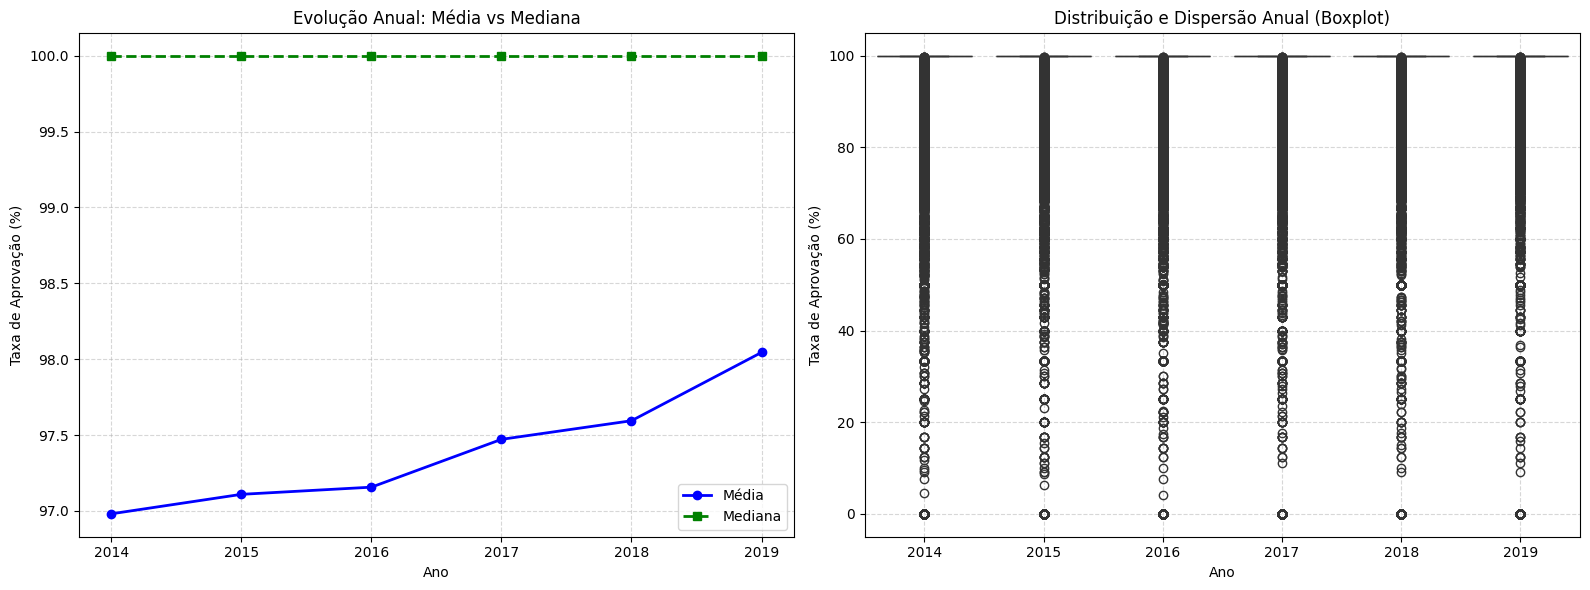

In [4]:
# 1. Calculando métricas anuais robustas (Média e Mediana)
stats_anuais = dataframe_filtrado.groupby("ANO")["Aprovação no 1º Ano do Ensino Fundamental"].agg(["mean", "median", "std"]).reset_index()
display(stats_anuais)

# 2. Criando subplots para avaliar a variação anual de forma robusta
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Linha comparativa de Média vs Mediana
axes[0].plot(stats_anuais["ANO"], stats_anuais["mean"], marker='o', label='Média', color='blue', linewidth=2)
axes[0].plot(stats_anuais["ANO"], stats_anuais["median"], marker='s', label='Mediana', color='green', linewidth=2, linestyle='--')
axes[0].set_title("Evolução Anual: Média vs Mediana")
axes[0].set_xlabel("Ano")
axes[0].set_ylabel("Taxa de Aprovação (%)")
axes[0].set_xticks(stats_anuais["ANO"])
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend()

# Subplot 2: Boxplot para visualizar a distribuição e assimetria (skewness)
sns.boxplot(ax=axes[1], x="ANO", y="Aprovação no 1º Ano do Ensino Fundamental", data=dataframe_filtrado, palette="Blues")
axes[1].set_title("Distribuição e Dispersão Anual (Boxplot)")
axes[1].set_xlabel("Ano")
axes[1].set_ylabel("Taxa de Aprovação (%)")
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [5]:
dataframe_normalizado = dataframe_filtrado.copy()

epsilon = 1e-6


dataframe_normalizado["Aprovação no 1º Ano do Ensino Fundamental"] = dataframe_normalizado["Aprovação no 1º Ano do Ensino Fundamental"]/100

dataframe_normalizado["Aprovação no 1º Ano do Ensino Fundamental"] = np.clip(dataframe_normalizado["Aprovação no 1º Ano do Ensino Fundamental"], epsilon, 1 - epsilon)

dataframe_normalizado["Aprovação no 1º Ano do Ensino Fundamental"] = np.log(dataframe_normalizado["Aprovação no 1º Ano do Ensino Fundamental"] / (1 - dataframe_normalizado["Aprovação no 1º Ano do Ensino Fundamental"]))



dataframe_pivotado = dataframe_normalizado.pivot_table(
    values="Aprovação no 1º Ano do Ensino Fundamental",
    index=["REGIAO","UF","CÓDIGO DO MUNICIPIO","REDE","CÓDIGO DA ESCOLA"],
    columns="ANO"
)

dataframe_pivotado.reset_index(inplace=True)
dataframe_pivotado.dropna(inplace=True)


dataframe_pivotado.rename(
    columns={
        "CÓDIGO DO MUNICIPIO":"codigo_municipio",
        "CÓDIGO DA ESCOLA":"codigo_escola",
        "REDE":"rede",
        "REGIAO":"regiao",
        "UF":"uf"
    },
    inplace=True
)
dataframe_pivotado.head()

#dataframe_pivotado.count()

ANO,regiao,uf,codigo_municipio,rede,codigo_escola,2014,2015,2016,2017,2018,2019
11284,Nordeste,AL,2700102,Municipal,27000281,13.815510,13.815510,13.815510,3.705409,13.81551,13.815510
11285,Nordeste,AL,2700102,Municipal,27000400,13.815510,3.102603,13.815510,13.815510,13.81551,3.346803
11286,Nordeste,AL,2700102,Municipal,27000613,13.815510,2.843852,2.402267,3.152319,13.81551,13.815510
11287,Nordeste,AL,2700102,Municipal,27046427,3.705409,13.815510,3.663562,3.102603,13.81551,3.748992
11288,Nordeste,AL,2700102,Municipal,27046435,3.842009,13.815510,13.815510,13.815510,13.81551,13.815510


In [6]:
dados = dataframe_pivotado[[2014, 2015, 2016, 2017, 2018, 2019]].to_numpy(dtype="float32")

# Features: 2014-2018
X = dados[:, :-1]

# Target: 2019
y = dados[:, -1:]

X = np.expand_dims(X, axis=-1)

dataset_train, dataset_test = keras.utils.split_dataset(
    (X, y),
    left_size=0.7,
    shuffle=True,
    seed=42
)

dataset_train = dataset_train.batch(24)
dataset_test = dataset_test.batch(24)


In [7]:
model = keras.Sequential([
    keras.Input(shape=(5, 1)),
    keras.layers.SimpleRNN(units=16,return_sequences=True),
    keras.layers.Dense(units=1,activation="linear")
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.MeanSquaredError(),
    metrics=[keras.metrics.MeanAbsoluteError()]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 5, 16)          │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5, 1)           │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 305 (1.19 KB)

 Trainable params: 305 (1.19 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
history = model.fit(
    dataset_train,
    validation_data=dataset_test,
    epochs=20
)

Epoch 1/20
1494/1494 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - loss: 43.1678 - mean_absolute_error: 5.4667 - val_loss: 17.9352 - val_mean_absolute_error: 3.1260
Epoch 2/20
1494/1494 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 17.1571 - mean_absolute_error: 2.9786 - val_loss: 17.3222 - val_mean_absolute_error: 2.9521
Epoch 3/20
1494/1494 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 16.8106 - mean_absolute_error: 2.9033 - val_loss: 17.0555 - val_mean_absolute_error: 2.9627
Epoch 4/20
1494/1494 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 16.6859 - mean_absolute_error: 2.8865 - val_loss: 16.9878 - val_mean_absolute_error: 3.0021
Epoch 5/20
1494/1494 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - loss: 16.6385 - mean_absolute_error: 2.8772 - val_loss: 16.9619 - val_mean_absolute_error: 3.0167
Epoch 6/20
1494/1494 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 16.6128 - mean_absolute_error: 2.8722 - val_loss: 16.9440 - val_mean_absolute_error: 3.0171
Epoch 7/20
1494/1494 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - loss: 16.5965 - mean

#VALIDACAO

In [9]:
# ==========================================================
# VALIDAÇÃO DO MODELO COM NORMALIZAÇÃO LOGIT
# Não retreina a rede.
# Utiliza model, dataset_train e dataset_test já existentes.
# ==========================================================

import numpy as np
import pandas as pd


# ----------------------------------------------------------
# Função inversa do Logit
# logit -> percentual [0, 100]
# ----------------------------------------------------------

def inversa_logit(valor):
    # Clip apenas para evitar overflow numérico no exp()
    valor = np.clip(valor, -50, 50)

    return 100 / (1 + np.exp(-valor))


# ----------------------------------------------------------
# Recupera os datasets NA ESCALA LOGIT
# ----------------------------------------------------------

X_train_logit = np.concatenate([
    x.numpy() for x, y in dataset_train
], axis=0)

y_train_logit = np.concatenate([
    y.numpy() for x, y in dataset_train
], axis=0).reshape(-1)


X_test_logit = np.concatenate([
    x.numpy() for x, y in dataset_test
], axis=0)

y_test_logit = np.concatenate([
    y.numpy() for x, y in dataset_test
], axis=0).reshape(-1)


# ----------------------------------------------------------
# Previsão
#
# IMPORTANTE:
# O modelo foi treinado em LOGIT, portanto recebe X em LOGIT.
# ----------------------------------------------------------

previsoes_logit = model.predict(
    X_test_logit,
    verbose=0
)


# return_sequences=True -> (amostras, timesteps, 1)
# Usamos somente a previsão do último timestep.
if previsoes_logit.ndim == 3:
    previsao_rnn_logit = previsoes_logit[:, -1, 0]
else:
    previsao_rnn_logit = previsoes_logit.reshape(-1)


# ----------------------------------------------------------
# RETORNO DA ESCALA LOGIT PARA 0-100
# ----------------------------------------------------------

y_train_percentual = inversa_logit(
    y_train_logit
)

y_test_percentual = inversa_logit(
    y_test_logit
)

X_test_percentual = inversa_logit(
    X_test_logit
)

previsao_rnn_percentual = inversa_logit(
    previsao_rnn_logit
)


# ----------------------------------------------------------
# Baselines
# Todos agora estão na mesma escala: 0-100
# ----------------------------------------------------------

# 1. Média do target no treino
previsao_media = np.full(
    len(y_test_percentual),
    np.mean(y_train_percentual)
)


# 2. Mediana do target no treino
previsao_mediana = np.full(
    len(y_test_percentual),
    np.median(y_train_percentual)
)


# 3. Persistência:
# previsão de 2019 = valor observado em 2018
previsao_ultimo_ano = X_test_percentual[:, -1, 0]


# 4. Média dos cinco anos anteriores
previsao_media_5_anos = np.mean(
    X_test_percentual[:, :, 0],
    axis=1
)


# ----------------------------------------------------------
# Métricas
# ----------------------------------------------------------

def calcular_mae(real, previsto):
    return np.mean(
        np.abs(real - previsto)
    )


def calcular_rmse(real, previsto):
    return np.sqrt(
        np.mean((real - previsto) ** 2)
    )


def calcular_r2(real, previsto):

    soma_residuos = np.sum(
        (real - previsto) ** 2
    )

    soma_total = np.sum(
        (real - np.mean(real)) ** 2
    )

    return 1 - (
        soma_residuos / soma_total
    )


# ----------------------------------------------------------
# Comparação
# ----------------------------------------------------------

modelos = {
    "RNN": previsao_rnn_percentual,
    "Média do treino": previsao_media,
    "Mediana do treino": previsao_mediana,
    "Último ano (2018)": previsao_ultimo_ano,
    "Média dos 5 anos": previsao_media_5_anos
}


resultados = []

for nome, previsao in modelos.items():

    resultados.append({

        "Modelo": nome,

        # Já estamos na escala 0-100.
        # NÃO multiplicar novamente por 100.
        "MAE (p.p.)": calcular_mae(
            y_test_percentual,
            previsao
        ),

        "RMSE (p.p.)": calcular_rmse(
            y_test_percentual,
            previsao
        ),

        "R²": calcular_r2(
            y_test_percentual,
            previsao
        )
    })


resultado_validacao = pd.DataFrame(resultados)

resultado_validacao = resultado_validacao.sort_values(
    "MAE (p.p.)"
).reset_index(drop=True)

display(
    resultado_validacao.round(4)
)


# ----------------------------------------------------------
# Skill da RNN em relação ao baseline 2019 = 2018
# ----------------------------------------------------------

mae_rnn = calcular_mae(
    y_test_percentual,
    previsao_rnn_percentual
)

mae_persistencia = calcular_mae(
    y_test_percentual,
    previsao_ultimo_ano
)

skill_rnn = 1 - (
    mae_rnn / mae_persistencia
)

print(
    f"Melhoria da RNN sobre o baseline "
    f"'2019 = 2018': {skill_rnn:.2%}"
)

,Modelo,MAE (p.p.),RMSE (p.p.),R²
0,RNN,1.9057,7.3353,-0.0584
1,Mediana do treino,1.9189,7.3839,-0.0724
2,Último ano (2018),2.7847,8.9199,-0.5650
3,Média dos 5 anos,2.9392,7.3245,-0.0553
4,Média do treino,3.1222,7.1303,-0.0000


Melhoria da RNN sobre o baseline '2019 = 2018': 31.57%
